In [13]:
#the imports 
from dotenv import load_dotenv
load_dotenv()
import uuid

from pydantic import BaseModel, Field
from typing import List

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage
from langchain_core.runnables import RunnableConfig

from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.store.memory import InMemoryStore
from langgraph.store.base import BaseStore

In [14]:
# creating the object for the store
store = InMemoryStore()

In [15]:
#creating the prompt: 

SYSTEM_PROMPT_TEMPLATE = """You are a helpful assistant with memory capabilities.
If user-specific memory is available, use it to personalize 
your responses based on what you know about the user.

Your goal is to provide relevant, friendly, and tailored 
assistance that reflects the user’s preferences, context, and past interactions.

If the user’s name or relevant personal context is available, always personalize your responses by:
    – Always Address the user by name (e.g., "Sure, Nitish...") when appropriate
    – Referencing known projects, tools, or preferences (e.g., "your MCP  server python based project")
    – Adjusting the tone to feel friendly, natural, and directly aimed at the user

Avoid generic phrasing when personalization is possible. For example, instead of "In TypeScript apps..." 
say "Since your project is built with TypeScript..."

Use personalization especially in:
    – Greetings and transitions
    – Help or guidance tailored to tools and frameworks the user uses
    – Follow-up messages that continue from past context

Always ensure that personalization is based only on known user details and not assumed.

In the end suggest 3 relevant further questions based on the current response and user profile

The user’s memory (which may be empty) is provided as: {user_details_content} """

In [16]:
# we will create 1st the memory extractor LLM
memory_llm = ChatGroq(model = "openai/gpt-oss-120b", temperature = 0.7)

In [17]:
# now we will create the two pydantic models so that there is no  redendency
class MemoryItem(BaseModel):
    text: str = Field(description = "Atomic user memory")
    is_new: bool = Field(description="true if new memory false if duplicate memory")
    

In [18]:
#pydantic model 2 containing the lisdt of memoryitem from above making this model expressive pydantic model
class MemoryDecision(BaseModel):
    should_store: bool
    memories: List[MemoryItem] = Field(default_factory=list)

In [19]:
memory_extractor = memory_llm.with_structured_output(MemoryDecision)

In [24]:
MEMORY_PROMPT = """You are responsible for updating and maintaining accurate user memory.

CURRENT USER DETAILS (existing memories):
{user_details_content}

TASK:
- Review the user's latest message.
- Extract user-specific info worth storing long-term (identity, stable preferences, ongoing projects/goals).
- For each extracted item, set is_new=true ONLY if it adds NEW information compared to CURRENT USER DETAILS.
- If it is basically the same meaning as something already present, set is_new=false.
- Keep each memory as a short atomic sentence.
- No speculation; only facts stated by the user.
- If there is nothing memory-worthy, return should_write=false and an empty list.
"""

In [25]:
#the remmemberance function
def remembrance_node(state: MessagesState, config: RunnableConfig, store: BaseStore):
    # taking the thread id:
    user_id = config["configurable"]["user_id"]
    
    # creating the namespace:
    namespace = ("user", user_id, "details")
    
    #getting the last message from the response
    #here we will be sending two things system message and the alst message
    last_message = state["messages"][-1].content
    
    #this memory decision is the object of our memory decision pydantic model.
    decision: MemoryDecision = memory_extractor.invoke([
        SystemMessage(
            content= (
                "extract the long term memory from the user messgae. \n"
                "only store stable and user-specific info (identity, preferences, ongoing projects) \n"
                "Do not store transient info \n"
                "return should_write = fasle if nothing is worth storing. \n"
                "each memory should be a short atomic sentence.")
        ),
        # so we are giving the system message plus the users last message here.
        {"role": "user", "content": last_message},
    ])
    
    #now we will check if the decision is to store or not
    if decision.should_store:
        for memory in decision.memories:
            store.put(namespace, str(uuid.uuid4()), {"data": memory})
            
            
    # also note that we are not using memory , not even responding with the LLM       
    # now we will hard code the messgae that we have noted to put this in the memory
    return {}

In [22]:
# creating llm for the chatnode
LLM_chat = ChatGroq(model = "openai/gpt-oss-120b", temperature = 0.7)

In [23]:
# the chatnode function
# now we will write our node function here
def chat_node(state: MessagesState, config: RunnableConfig, store: BaseStore):
    
    #this will get us the user id.
    user_id = config["configurable"]["user_id"]
    
    user_details = ("user", user_id, "details")
    # first we will search the store and get all the memories
    items = store.search(user_id)
    
    # now the below code would be for like convert memory items into a string blok for {user_details_content}
    # keep it dead simple for teaching.
    
    if items:
        user_details_content = "\n".join(f"-{it.value.get('data', "")}" for it in items)
    # with this we will get the memory block seperated by hypen if there 
    else:
        user_details_content =""  # else say prompt is empty
        
    #now we get all the memory in the form of a string 
    
    # now we will fill the system prompt using this memory
    system_prompt = SYSTEM_PROMPT_TEMPLATE.format(user_details_content=user_details_content)
    
    # we will make a system message with this prompt
    system_msg = SystemMessage(content=system_prompt)
    
    #now we will give this to llm
    response = LLM_chat.invoke([system_msg]+ state["messages"])
    
    return {"messages": [response]}

In [27]:
# building the graph
graph = StateGraph(MessagesState)

graph.add_node("remembrance_node", remembrance_node)
graph.add_node("chat_node", chat_node)

graph.add_edge(START, "remembrance_node")
graph.add_edge("remembrance_node", "chat_node")

graph.add_edge("chat_node", END)

chatbot = graph.compile(store=store)

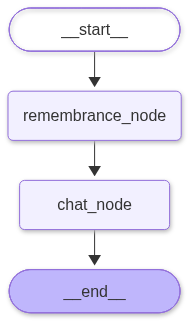

In [28]:
chatbot

In [29]:
config = {"configurable": {"user_id": "u1"}}

In [ ]:
# starting with the testing 